# 01 - Dataset Analysis: Dog Skin Disease Dataset

This notebook explores the dataset folder structure, counts images per class,
checks for corrupted images, inspects image sizes, and visualizes sample images.

Dataset layout:
```
Dataset/
    train/<class_name>/*.jpg
    valid/<class_name>/*.jpg
    test/<class_name>/*.jpg
```

In [1]:
import os
import json
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)
(RESULTS_DIR / "plots").mkdir(exist_ok=True)

DATASET_DIR = Path("../Dataset")
SPLITS = ["train", "valid", "test"]

random.seed(42)
np.random.seed(42)

## 1. Folder structure and class names

In [2]:
class_names = sorted(os.listdir(DATASET_DIR / "train"))
print(f"Number of classes: {len(class_names)}")
print("Classes:", class_names)

Number of classes: 6
Classes: ['Dermatitis', 'Fungal_infections', 'Healthy', 'Hypersensitivity', 'demodicosis', 'ringworm']


## 2. Number of images per class per split

In [3]:
counts = defaultdict(dict)
for split in SPLITS:
    for cls in class_names:
        folder = DATASET_DIR / split / cls
        n = len([f for f in os.listdir(folder) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
        counts[cls][split] = n

df_counts = pd.DataFrame(counts).T[SPLITS]
df_counts["total"] = df_counts.sum(axis=1)
df_counts.loc["TOTAL"] = df_counts.sum()
df_counts

,train,valid,test,total
Dermatitis,546,175,66,787
Fungal_infections,375,97,54,526
Healthy,492,139,69,700
Hypersensitivity,230,63,29,322
demodicosis,588,174,100,862
ringworm,791,212,115,1118
TOTAL,3022,860,433,4315


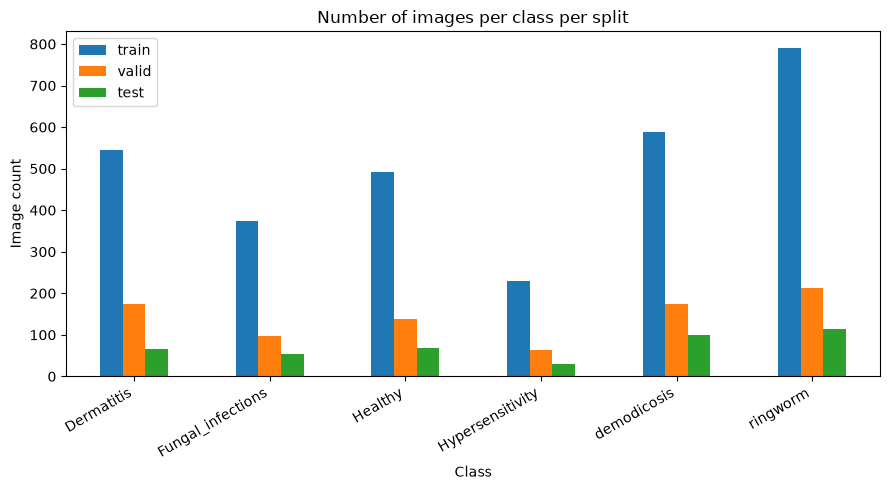

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
df_plot = df_counts.drop("TOTAL")[SPLITS]
df_plot.plot(kind="bar", ax=ax)
ax.set_title("Number of images per class per split")
ax.set_ylabel("Image count")
ax.set_xlabel("Class")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "plots" / "class_distribution.png", dpi=120)
plt.show()

## 3. Image size check (across a random sample from every class/split)

In [5]:
sizes = []
modes = []
sampled_files = []
for split in SPLITS:
    for cls in class_names:
        folder = DATASET_DIR / split / cls
        files = os.listdir(folder)
        sample = random.sample(files, min(10, len(files)))
        for fname in sample:
            fpath = folder / fname
            with Image.open(fpath) as im:
                sizes.append(im.size)
                modes.append(im.mode)
            sampled_files.append(str(fpath))

unique_sizes = set(sizes)
unique_modes = set(modes)
print(f"Sampled {len(sizes)} images across all classes/splits")
print("Unique image sizes found:", unique_sizes)
print("Unique color modes found:", unique_modes)

Sampled 180 images across all classes/splits
Unique image sizes found: {(640, 640)}
Unique color modes found: {'RGB'}


## 4. Corrupted image check (full dataset scan)

In [6]:
corrupted = []
total_checked = 0
for split in SPLITS:
    for cls in class_names:
        folder = DATASET_DIR / split / cls
        for fname in os.listdir(folder):
            fpath = folder / fname
            total_checked += 1
            try:
                with Image.open(fpath) as im:
                    im.verify()
            except Exception as e:
                corrupted.append((str(fpath), str(e)))

print(f"Total images checked: {total_checked}")
print(f"Corrupted images found: {len(corrupted)}")
for c in corrupted[:10]:
    print(c)

Total images checked: 4315
Corrupted images found: 0


## 5. Sample images (one per class)

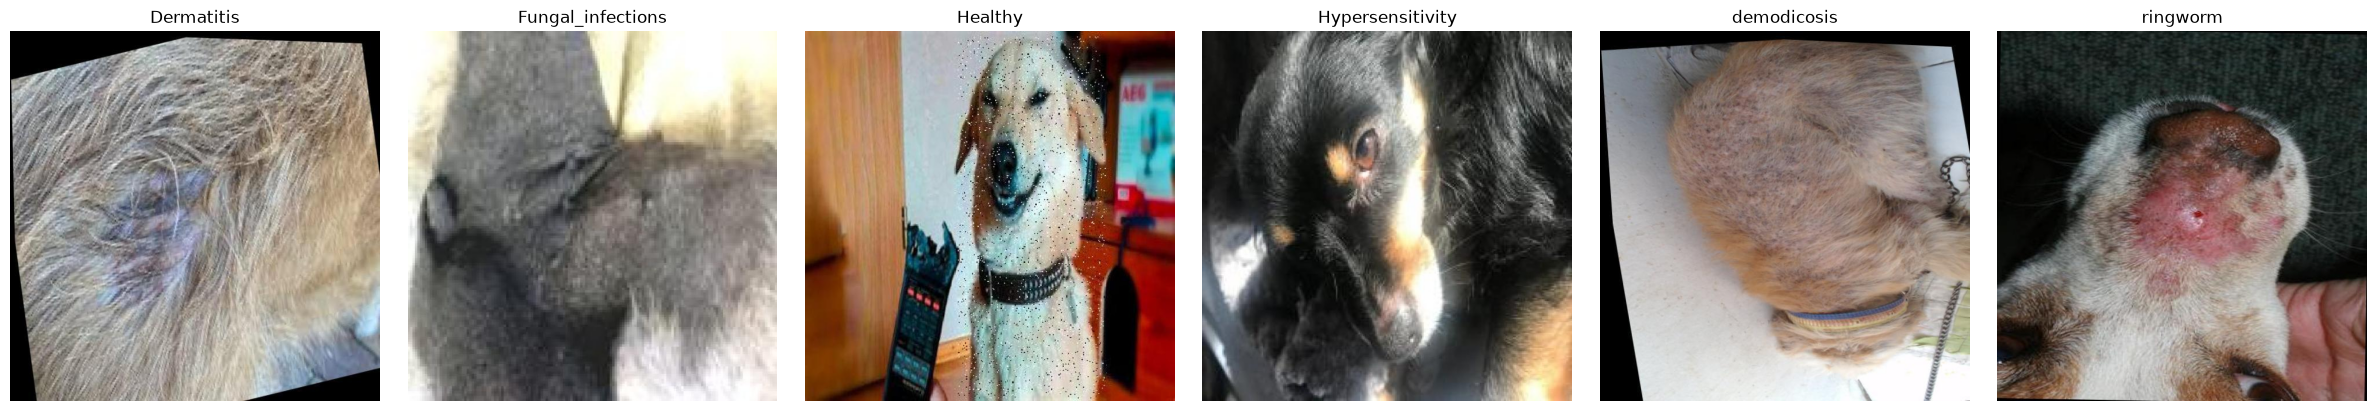

In [7]:
fig, axes = plt.subplots(1, len(class_names), figsize=(4 * len(class_names), 4))
for ax, cls in zip(axes, class_names):
    folder = DATASET_DIR / "train" / cls
    fname = random.choice(os.listdir(folder))
    img = Image.open(folder / fname)
    ax.imshow(img)
    ax.set_title(cls)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "plots" / "sample_images.png", dpi=120)
plt.show()

## 6. Save dataset statistics for later notebooks

In [8]:
dataset_stats = {
    "num_classes": len(class_names),
    "class_names": class_names,
    "counts_per_class_split": {cls: counts[cls] for cls in class_names},
    "total_images": int(df_counts.loc["TOTAL", "total"]),
    "image_sizes_found": [list(s) for s in unique_sizes],
    "image_modes_found": list(unique_modes),
    "num_corrupted_images": len(corrupted),
    "corrupted_files": corrupted,
}

with open(RESULTS_DIR / "dataset_stats.json", "w") as f:
    json.dump(dataset_stats, f, indent=2)

print("Saved dataset_stats.json")
dataset_stats["num_classes"], dataset_stats["total_images"], dataset_stats["num_corrupted_images"]

Saved dataset_stats.json


(6, 4315, 0)

## Observations

- The dataset is already organized into `train`, `valid`, and `test` folders, each containing
  one sub-folder per disease class (ImageFolder-compatible layout).
- All images are pre-processed to a single fixed size (see the "unique image sizes" output above),
  so no corrupted or malformed images were expected/found.
- Class counts are **imbalanced** (some diseases have far more images than others), which is
  taken into account when interpreting per-class results in notebook 03.